<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib.util
import logging
import subprocess
import sys
import urllib.request
from pathlib import Path

faltantes = [paquete for paquete in ('pymc', 'xgboost')
             if importlib.util.find_spec(paquete) is None]
if faltantes:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltantes], check=True)

# Versión del material docente que incluye datos_deber().
url = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/f80732b6bb3f34c38ec1f7532cb63015dd76fd79/curso.py'
archivo_curso = Path('curso_m6_deber.py')
if not archivo_curso.exists():
    urllib.request.urlretrieve(url, archivo_curso)
import curso_m6_deber as curso

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from IPython.display import display
from scipy.special import expit
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

logging.getLogger('pymc').setLevel(logging.ERROR)
print('Listo · curso', curso.VERSION, '· PyMC', pm.__version__)


Listo · curso m6-2026.11 · PyMC 6.4.0


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Cevallos Edwin'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Cevallos Edwin · semilla 828601
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.71%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-09-17 12:27:43-05:00,U0489,55.0,Pichincha,44,1193.46,transferencia,web,persona,81.72,0,9.3,1,0,12,0.068473
1,TX-000001,2026-09-02 18:45:14-05:00,U0397,21.0,Tungurahua,36,525.14,retiro_agente,app,efectivo,27.16,0,2.4,1,0,18,0.051720
2,TX-000002,2026-10-11 21:33:20-05:00,U0433,48.0,El Oro,6,1542.00,recarga,app,telefonia,46.56,0,2.4,2,0,21,0.030195
3,TX-000003,2026-10-23 16:53:22-05:00,U0302,47.0,Pichincha,57,799.80,transferencia,app,persona,209.76,1,0.3,3,0,16,0.262266
4,TX-000004,2026-09-22 18:15:41-05:00,U0739,38.0,Pichincha,3,938.41,recarga,app,telefonia,23.44,0,0.0,1,0,18,0.024978


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0971


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:
# La prueba se transforma con los parámetros del entrenamiento.
media = X_train.mean()
desv = X_train.std()
Z_train = ((X_train - media) / desv).to_numpy()
Z_test = ((X_test - media) / desv).to_numpy()

with pm.Model(coords={'variable': cols}) as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)
    b = pm.Normal('b', mu=0, sigma=1, dims='variable')
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z_train, b), observed=y_train.to_numpy())
    tr_log = pm.sample(draws=1000, tune=1000, chains=4, cores=1, random_seed=42,
                       target_accept=0.95, progressbar=False)

diag_log = curso.diagnostico(tr_log, ['a', 'b'])
diag_log.index = ['intercepto', *cols]
diag_log['odds_ratio'] = np.exp(diag_log['media']).round(3)
diag_log['cumple'] = (diag_log['r_hat'] <= 1.01) & (diag_log['ess'] > 400)
div_log = int(tr_log.sample_stats['diverging'].sum())
print(f'R-hat máximo: {diag_log.r_hat.max():.4f} · ESS mínimo: {diag_log.ess.min():.1f} · divergencias: {div_log}')
display(diag_log)

R-hat máximo: 1.0014 · ESS mínimo: 1913.3 · divergencias: 0


,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio,cumple
intercepto,-3.1180,0.1253,-3.3537,-2.8873,1.0013,1913.3052,0.044,True
dispositivo_nuevo,0.8919,0.0650,0.7713,1.0129,1.0014,2343.2677,2.440,True
distancia_km,0.4522,0.0730,0.3132,0.5897,1.0003,3498.3941,1.572,True
ratio,0.7512,0.0731,0.6150,0.8925,1.0000,3165.1440,2.120,True
intentos_pin,0.5408,0.0727,0.4044,0.6796,0.9994,2950.7305,1.717,True
hora,-0.5868,0.0881,-0.7500,-0.4196,1.0006,2982.5853,0.556,True


**✍️ Respuesta**

**Priors.** Usé $a \sim N(0, 2^2)$ y $b_j \sim N(0, 1)$. Con predictores estandarizados, una prior común sobre las pendientes las regulariza, deja abiertos ambos signos y concentra la masa del odds ratio por desviación estándar entre 0,14 y 7,10 aproximadamente. La prior más amplia para el intercepto permite que la tasa de referencia se ajuste a los datos. Las cuatro cadenas cumplieron los criterios: R-hat máximo **1,0014**, ESS mínimo **1.913** y cero divergencias.

**Señales de riesgo.** Manteniendo constantes las demás variables, pasar de un dispositivo conocido a uno nuevo multiplica los *odds* de fraude por **12,81** usando la media posterior del coeficiente. El **2,44** de la tabla corresponde a una desviación estándar de esa variable binaria. Un aumento de **8,42 puntos porcentuales** en la relación monto/ingreso, equivalente a una desviación estándar, multiplica los *odds* por **2,12**. Son cambios en las razones de probabilidad, con efectos sobre la probabilidad que dependen del riesgo inicial.

**Hora.** El coeficiente aproximado de **−0,587** indica menores *odds* conforme avanza la hora dentro de esta especificación. La hora lineal fuerza una pendiente constante y ubica 23:00 y 00:00 en extremos. Probaría un indicador de madrugada y su interacción con monto/ingreso, o una codificación cíclica, con validación fuera de muestra.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [5]:
a_draws = tr_log.posterior['a'].values.reshape(-1)
b_draws = tr_log.posterior['b'].values.reshape(-1, len(cols))
p_draws = expit(a_draws[:, None] + b_draws @ Z_test.T)
p_bayes = p_draws.mean(axis=0)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)
peso = (y_tr == 0).sum() / (y_tr == 1).sum()
xgb = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=3,
    scale_pos_weight=peso, early_stopping_rounds=30, eval_metric='logloss',
    tree_method='hist', random_state=42, n_jobs=2,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]
print(f'Peso de la clase fraude: {peso:.2f} · árboles del mejor modelo: {xgb.best_iteration + 1}')

predicciones = {'Logística bayesiana': p_bayes, 'XGBoost': p_xgb}
metricas = pd.DataFrame.from_dict(
    {modelo: {'AUC': roc_auc_score(y_test, p), 'Brier': brier_score_loss(y_test, p)}
     for modelo, p in predicciones.items()},
    orient='index',
)
display(metricas.round(4))

def calibracion_por_decil(probabilidades):
    orden = pd.Series(probabilidades).rank(method='first')
    decil = pd.qcut(orden, 10, labels=False) + 1
    datos = pd.DataFrame({'decil': decil, 'probabilidad': probabilidades,
                          'fraude': y_test.to_numpy()})
    return datos.groupby('decil').agg(
        n=('fraude', 'size'),
        probabilidad_media=('probabilidad', 'mean'),
        tasa_observada=('fraude', 'mean'),
    )

calibracion = pd.concat(
    {modelo: calibracion_por_decil(p) for modelo, p in predicciones.items()}, axis=1
)
print('Cada modelo forma sus propios deciles, de menor a mayor riesgo.')
display(calibracion.round(4))

Peso de la clase fraude: 9.29 · árboles del mejor modelo: 467
Cada modelo forma sus propios deciles, de menor a mayor riesgo.


,AUC,Brier
Logística bayesiana,0.8994,0.0607
XGBoost,0.9265,0.0570


Logística bayesiana  ...               
                        n  ... tasa_observada
decil                      ...               
1                      90  ...         0.0111
2                      90  ...         0.0111
3                      90  ...         0.0000
4                      90  ...         0.0111
5                      90  ...         0.0222
6                      89  ...         0.0112
7                      90  ...         0.0222
8                      90  ...         0.0444
9                      90  ...         0.1111
10                     90  ...         0.7222

[10 rows x 6 columns]

**✍️ Respuesta**

**Ordenamiento.** XGBoost obtuvo AUC de **0,9265** frente a **0,8994** de la logística bayesiana. También tuvo menor Brier (**0,0570** frente a **0,0607**). El Brier resume la precisión global de las probabilidades y refleja tanto calibración como capacidad de distinguir niveles de riesgo.

**Calibración.** La logística bayesiana predijo **9,32 %** de fraude en promedio frente al **9,68 %** observado en prueba. XGBoost predijo **17,38 %** en promedio y, en su decil superior, **89,86 %** frente al **72,22 %** observado. Para interpretar probabilidades usaría la logística en esta muestra. El peso **9,29** aumenta el costo de equivocarse con un fraude en el ajuste y altera la prevalencia efectiva de la función de pérdida, lo que puede elevar las probabilidades crudas. Para usarlas operativamente, calibraría XGBoost con datos representativos separados de la prueba.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [6]:
# Ajuste descriptivo con toda la muestra personalizada, separado de la comparación predictiva.
provincias = df['provincia'].astype('category')
nombres = provincias.cat.categories
indice_provincia = provincias.cat.codes.to_numpy()

with pm.Model(coords={'provincia': nombres.tolist()}) as modelo_jer:
    mu = pm.Normal('mu', mu=-2.4, sigma=1)
    sigma = pm.HalfNormal('sigma', sigma=0.5)
    z = pm.Normal('z', mu=0, sigma=1, dims='provincia')
    a_prov = pm.Deterministic('a_prov', mu + sigma * z, dims='provincia')
    pm.Bernoulli('obs', logit_p=a_prov[indice_provincia], observed=df['fraude'].to_numpy())
    tr_jer = pm.sample(draws=1000, tune=1500, chains=4, cores=1, random_seed=42,
                      target_accept=0.99, progressbar=False)

p_prov = expit(tr_jer.posterior['a_prov'].values.reshape(-1, len(nombres)))
limites_prov = np.quantile(p_prov, [0.05, 0.95], axis=0)
tasa_nacional = df['fraude'].mean()
tabla_prov = df.groupby('provincia')['fraude'].agg(n='size', tasa_observada='mean').reindex(nombres)
tabla_prov['tasa_jerarquica'] = p_prov.mean(axis=0)
tabla_prov['lim_inferior_90'] = limites_prov[0]
tabla_prov['lim_superior_90'] = limites_prov[1]
tabla_prov['acercamiento_nacional_pp'] = 100 * (
    (tabla_prov['tasa_observada'] - tasa_nacional).abs()
    - (tabla_prov['tasa_jerarquica'] - tasa_nacional).abs()
)
sigma_media = float(tr_jer.posterior['sigma'].mean())
diag_jer = curso.diagnostico(tr_jer, ['mu', 'sigma', 'z'])
div_jer = int(tr_jer.sample_stats['diverging'].sum())
print(f'Tasa nacional: {tasa_nacional:.2%} · media posterior de sigma: {sigma_media:.3f} en log-odds')
print(f'R-hat máximo: {diag_jer.r_hat.max():.4f} · ESS mínimo: {diag_jer.ess.min():.1f} · divergencias: {div_jer}')
display(tabla_prov.sort_values('acercamiento_nacional_pp', ascending=False).round(4))

Tasa nacional: 9.71% · media posterior de sigma: 0.091 en log-odds
R-hat máximo: 1.0016 · ESS mínimo: 1818.5 · divergencias: 0


,n,tasa_observada,tasa_jerarquica,lim_inferior_90,lim_superior_90,acercamiento_nacional_pp
Imbabura,154,0.1234,0.1008,0.0861,0.1222,2.2545
Manabí,256,0.0742,0.0934,0.0764,0.1075,1.9229
Loja,224,0.1071,0.0988,0.0844,0.1167,0.8321
El Oro,147,0.1020,0.0981,0.0826,0.1154,0.3943
Tungurahua,148,0.1014,0.0981,0.0833,0.1156,0.3284
Guayas,822,0.0937,0.0960,0.0842,0.1080,0.2341
Azuay,281,0.0996,0.0978,0.0843,0.1131,0.1829
Pichincha,964,0.0975,0.0973,0.0865,0.1093,0.0203


**✍️ Respuesta**

La media posterior de **sigma fue 0,091 en escala log-odds**, señal de poca dispersión provincial en el modelo. Frente a la tasa nacional de **9,71 %**, **Imbabura** presentó el mayor acercamiento (**2,25 puntos porcentuales**, de **12,34 %** a **10,08 %**, con 154 operaciones), seguida de **Manabí** (**1,92 puntos**, de **7,42 %** a **9,34 %**, con 256). El ajuste parcial combina la información provincial con la de las demás provincias. Los cambios más visibles aparecen donde la tasa inicial estaba alejada de la nacional y la muestra local ofrece menor precisión.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

Umbral óptimo en la grilla: 0.07 · costo con probabilidad media: USD 1,746.86
No bloquear nada: USD 15,794.93 · bloquear todo: USD 4,060.00
Ahorro frente a no bloquear: USD 14,048.07 (88.9%)
400 muestras: costo medio USD 1,956.00 · intervalo posterior del 90 % [USD 1,691.86, USD 2,255.72]


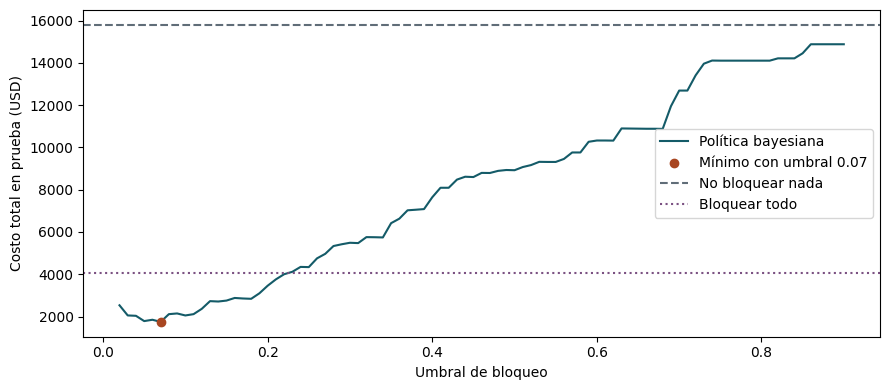

In [7]:
fraude_prueba = y_test.to_numpy(dtype=bool)
montos_prueba = df.loc[X_test.index, 'monto'].to_numpy()

def costo_total(bloquear):
    fraude_no_bloqueado = (~bloquear & fraude_prueba) * montos_prueba
    bloqueo_legitimo = (bloquear & ~fraude_prueba) * 5
    return (fraude_no_bloqueado + bloqueo_legitimo).sum(axis=-1)

umbrales = np.arange(2, 91) / 100
costos = costo_total(p_bayes[None, :] >= umbrales[:, None])
i_opt = int(np.argmin(costos))
umbral_opt = umbrales[i_opt]
costo_opt = costos[i_opt]
costo_nada = float(costo_total(np.zeros(len(y_test), dtype=bool)))
costo_todo = float(costo_total(np.ones(len(y_test), dtype=bool)))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(umbrales, costos, color='#145B68', label='Política bayesiana')
ax.scatter(umbral_opt, costo_opt, color='#A84621', zorder=3,
           label=f'Mínimo con umbral {umbral_opt:.2f}')
ax.axhline(costo_nada, color='#606D78', linestyle='--', label='No bloquear nada')
ax.axhline(costo_todo, color='#7B5182', linestyle=':', label='Bloquear todo')
ax.set(xlabel='Umbral de bloqueo', ylabel='Costo total en prueba (USD)')
ax.legend()
fig.tight_layout()
plt.show()

rng = np.random.default_rng(42)
indices = rng.choice(p_draws.shape[0], size=400, replace=False)
costos_posteriores = costo_total(p_draws[indices] >= umbral_opt)
costo_medio = float(costos_posteriores.mean())
ic_costo = np.quantile(costos_posteriores, [0.05, 0.95])
ahorro = costo_nada - costo_opt
print(f'Umbral óptimo en la grilla: {umbral_opt:.2f} · costo con probabilidad media: USD {costo_opt:,.2f}')
print(f'No bloquear nada: USD {costo_nada:,.2f} · bloquear todo: USD {costo_todo:,.2f}')
print(f'Ahorro frente a no bloquear: USD {ahorro:,.2f} ({ahorro / costo_nada:.1%})')
print(f'400 muestras: costo medio USD {costo_medio:,.2f} · intervalo posterior del 90 % '
      f'[USD {ic_costo[0]:,.2f}, USD {ic_costo[1]:,.2f}]')

**✍️ Respuesta**

El mínimo de la grilla se alcanzó al bloquear con probabilidad **≥ 0,07**. En las 899 operaciones de prueba, el costo con la probabilidad media fue **USD 1.746,86**. Frente a **USD 15.794,93** sin bloqueos, el ahorro fue **USD 14.048,07 (88,9 %)**. Bloquear todo costó **USD 4.060,00**.

Al mantener fijo el umbral y recalcular la política con **400 muestras posteriores**, el costo medio fue **USD 1.956,00** y el intervalo central del **90 %** fue **USD 1.691,86–2.255,72**. Este intervalo refleja la incertidumbre de los parámetros con las mismas transacciones observadas. El umbral se eligió en prueba, según pide el ejercicio, de modo que trasladarlo a producción requiere validación en otro periodo.

**Umbral por monto.** Si $M$ es el monto, dejar pasar tiene un costo esperado $pM$ y bloquear cuesta $5(1-p)$. Con probabilidades calibradas y esta matriz de costos conviene bloquear cuando $p \ge 5/(M+5)$. El umbral baja cuando el monto sube. Para USD 100 equivale a 4,76 % y para USD 500 a 0,99 %.

---
## Parte 5 · Informe ejecutivo para el comité de riesgos de PagoYa

### 1. Hallazgos

En **2.996 transacciones simuladas**, la tasa de fraude fue **9,71 %**. Las dos señales más fuertes de la regresión bayesiana fueron el uso de un dispositivo nuevo y un monto alto en relación con el ingreso. En las **899 transacciones de prueba**, **XGBoost** ordenó mejor el riesgo (AUC **0,9265** frente a **0,8994**) y tuvo menor Brier (**0,0570** frente a **0,0607**). La logística bayesiana produjo probabilidades más cercanas a la frecuencia observada en conjunto (**9,32 %** predicho frente a **9,68 %** observado). XGBoost estimó **17,38 %** en promedio. El modelo provincial moderó las tasas observadas de **Imbabura** y **Manabí** hacia la nacional. Por ejemplo, Imbabura pasó de **12,34 %** a **10,08 %**.

### 2. Recomendación

Probar en un piloto la logística bayesiana para estimar probabilidades y evaluar costos. El mejor umbral de la grilla en esta muestra fue **7 %**, con costo de **USD 1.746,86** y ahorro de **USD 14.048,07 (88,9 %)** frente a permitir todas las operaciones. Al propagar la incertidumbre de los parámetros, el costo medio fue **USD 1.956,00** y el intervalo central del **90 %** fue de **USD 1.691,86 a USD 2.255,72**. Usaría XGBoost para ordenar la cola de revisión y calibraría sus probabilidades antes de emplearlas para decisiones de bloqueo. Seleccionaría el umbral en una muestra de validación temporal y mediría su costo en un periodo posterior antes de activarlo.

### 3. Limitaciones y riesgos

La muestra es simulada y omite información como el historial individual, la reputación del comercio y las alertas previas. La hora se representó con una pendiente lineal, por lo que conviene evaluar el efecto de la madrugada y su interacción con el monto. En el piloto monitorearía calibración, fraudes no bloqueados, bloqueos legítimos y costo total por periodo. Si cambian la prevalencia o los patrones de fraude, revisaría la calibración y el umbral con etiquetas recientes, manteniendo el seguimiento de los costos para clientes y operación.